[Open in Colab](https://colab.research.google.com/github/nz-gravity/sgvb_psd/blob/main/docs/examples/ET_example.ipynb)

# ET example

Fit the existing three-channel ET noise sample in the 5–100 Hz band.
Use 64 seconds to construct a fixed VAR(128) **full matrix reference**, the
next 128 seconds for SGVB, and the final 64 seconds for a held-out check.
The full reference retains narrow cross-channel features that a diagonal
baseline plus a very small cosine basis can miss.

The 16 MB sample is cached. Anti-aliased downsampling to 256 Hz, four-second
energy-normalized Hann blocks and a small residual basis keep this suitable
for a CPU demonstration. Saved figures show PSDs, native-resolution coherence and optimization
diagnostics. The paper’s Case-A coherence model is reconstructed below as
a separate comparison.


This is a compact **Case A** example from
[Section IV / Figure 7 of Liu et al.](https://arxiv.org/html/2409.13224v1#S4):
the shared Gaussian components produce X–Y coherence near **10 Hz**, X–Z
near **50 Hz**, and Y–Z near **90 Hz**. The bundled channels were verified
to equal the first 524,288 samples of each
[original paper data file](https://github.com/nz-gravity/sgvb_psd_paper/tree/037d93d189be0036fbb305aa60047260d5d16ee4/data).
The wider band shows both sides of the 10 Hz bump. Native-resolution
coherence is plotted without additional frequency smoothing.


## Setup

In [1]:
# Colab installs the package; local runs use the project environment.
import subprocess
import sys

try:
    import google.colab
except ImportError:
    print("Using the local SGVB environment. See the repository's uv setup instructions.")
else:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "jax[cpu]==0.6.2", "numpyro==0.19.0",
        "sgvb_psd[examples] @ git+https://github.com/nz-gravity/sgvb_psd.git@main",
    ])


Using the local SGVB environment. See the repository's uv setup instructions.


In [2]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found.*")
from pathlib import Path
from time import perf_counter
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sgvb_psd.psd_estimator import PSDEstimator
from sgvb_psd.ar_reference import fit_ar_reference
import jax

%matplotlib inline
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11,
    "axes.labelsize": 11, "axes.titlesize": 12, "legend.fontsize": 8,
    "figure.dpi": 110, "text.usetex": False})
print("JAX", jax.__version__, "devices:", jax.devices())
# Fixed budgets: no order or learning-rate search on the validation segment.
BUDGET = dict(N_theta=48, ntrain_map=1500, n_elbo_maximisation_steps=2000,
              optimize_mean=True, elbo_samples=4, N_samples=128, seed=7)


21:49:53|SGVB-PSD|INFO| No GPU detected. Running on CPU.
JAX 0.6.2 devices: [CpuDevice(id=0)]


## Separate training, analysis and validation blocks

In [3]:
import h5py
from urllib.request import urlopen
import shutil

DATA_PATH = Path("et_data.h5")
if not DATA_PATH.exists():
    url = "https://raw.githubusercontent.com/nz-gravity/sgvb_psd/c2b20d1426d260c1472e44cc008ff73af4c7c874/docs/examples/et_data.h5"
    temporary = DATA_PATH.with_suffix(".part")
    with urlopen(url, timeout=60) as response, temporary.open("wb") as destination:
        shutil.copyfileobj(response, destination)
    temporary.replace(DATA_PATH)
with h5py.File(DATA_PATH, "r") as handle:
    raw = np.column_stack([handle[k][:] for k in ("X", "Y", "Z")])
fs = 256.
BLOCK_SAMPLES = 1024  # four seconds; the Fourier resolution is 0.25 Hz.
reduced = signal.resample_poly(raw, up=1, down=8, axis=0)
assert reduced.shape == (65536, 3) and np.all(np.isfinite(reduced))
def taper_blocks(values, block_samples):
    """Center each block and apply a unit-mean-square periodic Hann window."""
    blocks = values.reshape(-1, block_samples, values.shape[1])
    window = signal.windows.hann(block_samples, sym=False)
    window /= np.sqrt(np.mean(window**2))
    nbw = block_samples*np.sum(window**2)/np.sum(window)**2
    result = ((blocks-blocks.mean(axis=1, keepdims=True))*window[None, :, None])
    return result.reshape(values.shape), nbw

training, nbw = taper_blocks(reduced[:64*256], BLOCK_SAMPLES)
data, _ = taper_blocks(reduced[64*256:192*256], BLOCK_SAMPLES)
heldout, _ = taper_blocks(reduced[192*256:], BLOCK_SAMPLES)
assert np.isclose(nbw, 1.5)
start = perf_counter()
reference = fit_ar_reference(training, fs, order=128, full_matrix=True)
ar_seconds = perf_counter()-start
print(f"Fixed VAR({reference.order}) reference: {ar_seconds:.3f} s; full {reference.n_channels}×{reference.n_channels} S(f)")
print("Training / analysis / held-out samples:", training.shape, data.shape, heldout.shape)


Fixed VAR(128) reference: 0.004 s; full 3×3 S(f)
Training / analysis / held-out samples: (16384, 3) (32768, 3) (16384, 3)


## Fit the residual spectral matrix

In [4]:
# Native likelihood bins are cheap for this example. For much longer data,
# coarse_grain=CoarseGrainConfig(...) is an optional approximation to check.
start = perf_counter()
estimator = PSDEstimator(data, fs=fs, reference_psd=reference,
    parallel_rows=True, nchunks=len(data)//BLOCK_SAMPLES, Nbw=nbw,
    fmin_for_analysis=5., fmax_for_analysis=100., **BUDGET)
_ = estimator.run(lr=.001)
fit_seconds = perf_counter()-start
assert np.isfinite(estimator.pointwise_ci).all()
print(f"{len(data)} samples × {data.shape[1]} channels; {estimator.nchunks} blocks; fit + compilation + draws {fit_seconds:.2f} s")
print("Independent vmapped Cholesky-row dimensions:", estimator.inference_runner.row_dimensions)


21:49:53|SGVB-PSD|INFO| Dividing data (32768, 3) into (32, 1024, 3) chunks
21:49:53|SGVB-PSD|INFO| Reducing the number of frequencies to be analyzed from 512 to 100.0...
21:49:53|SGVB-PSD|INFO| Final PSD will be of shape: 380 x 3 x 3
21:49:53|SGVB-PSD|WARNING| Input data not standardised!
21:49:53|SGVB-PSD|INFO| Using provided learning rate: 0.001
21:49:53|SGVB-PSD|INFO| Training model
21:49:59|SGVB-PSD|INFO| Model trained in 5.35s
21:49:59|SGVB-PSD|INFO| Computing posterior PSDs
32768 samples × 3 channels; 32 blocks; fit + compilation + draws 7.15 s
Independent vmapped Cholesky-row dimensions: (99, 300, 501)


## Spectra and held-out checks

Bands are 90% variational intervals conditional on the independently fitted
VAR reference. The coherence is computed **for every posterior draw at each
native frequency**, then summarized. No nine-bin smoothing is applied: it
would damp the Gaussian peaks. Grey empirical coherence is noisy and has a
positive finite-block noise floor; it is not a truth curve.

The dashed Case-A comparison uses the paper's ET sensitivity and Gaussian
components, transformed through the downsampling filter and the approximate
three-bin Hann spectral window. It is used only for comparison, after the
SGVB fit; it is not the inference reference. This short excerpt is not the
full 2,000-second paper analysis.


In [5]:
from hashlib import sha256
from urllib.request import urlopen
import shutil

PAPER_REVISION = "037d93d189be0036fbb305aa60047260d5d16ee4"
ASD_PATH = Path("data/ET_paper_design_ASD.txt")
ASD_PATH.parent.mkdir(exist_ok=True)
if not ASD_PATH.exists():
    url = f"https://raw.githubusercontent.com/nz-gravity/sgvb_psd_paper/{PAPER_REVISION}/data/ET(1).txt"
    temporary = ASD_PATH.with_suffix(".part")
    with urlopen(url, timeout=60) as response, temporary.open("wb") as destination:
        shutil.copyfileobj(response, destination)
    temporary.replace(ASD_PATH)
assert sha256(ASD_PATH.read_bytes()).hexdigest() == "11559a2f9accc5ea8a13857da6a8eff13bb169f9f5b480232e08e7faca5d767d"
assert sha256(DATA_PATH.read_bytes()).hexdigest() == "08913c703c3a6b6aa540518b359b6876326bb81119de8726f124f950eedf3fb3"
asd_table = np.loadtxt(ASD_PATH)
assert np.isfinite(asd_table).all() and (asd_table > 0).all()
assert (np.diff(asd_table[:, 0]) > 0).all()
GAUSSIAN_FEATURES = [(0, 1, 10., 4e-24), (0, 2, 50., 2e-24), (1, 2, 90., 1.5e-24)]

def paper_input_psd(frequencies):
    """Case A, Eq. 19: independent ET noise plus three shared Gaussian terms."""
    f = np.asarray(frequencies)
    assert np.all((f >= asd_table[0, 0]) & (f <= asd_table[-1, 0]))
    asd = np.exp(np.interp(np.log(f), np.log(asd_table[:, 0]), np.log(asd_table[:, 1])))
    spectrum = asd[:, None, None]**2*np.eye(3)[None]/2  # one-sided ASD -> two-sided PSD
    for i, j, center, amplitude in GAUSSIAN_FEATURES:
        power = amplitude**2/(4*np.pi)*np.exp(-(f-center)**2)
        for row, column in [(i, i), (j, j), (i, j), (j, i)]:
            spectrum[:, row, column] += power
    return spectrum

# The default resample_poly(up=1, down=8) filter; physical PSD/Hz alias sums
# do not require another factor of eight. Mean-square window gain is already one.
decimation_filter = signal.firwin(161, 1/8, window=("kaiser", 5.))
def paper_downsampled_psd(frequencies):
    f = np.asarray(frequencies)
    aliases = (f[:, None] + fs*np.arange(8) + 1024) % 2048 - 1024
    _, response = signal.freqz(decimation_filter, worN=aliases.ravel(), fs=2048.)
    original = paper_input_psd(abs(aliases).ravel()).reshape(len(f), 8, 3, 3)
    return np.sum(original*abs(response.reshape(len(f), 8))[:, :, None, None]**2, axis=1)

df = fs/BLOCK_SAMPLES
paper_comparison = (2/3*paper_downsampled_psd(estimator.freq)
    + 1/6*paper_downsampled_psd(estimator.freq-df)
    + 1/6*paper_downsampled_psd(estimator.freq+df))
assert np.all(np.linalg.eigvalsh(paper_comparison) > 0)


In [6]:
COLORS = dict(fit="#1764a0", reference="#ae7c00", heldout="#303030")

def spectral_average(values, nperseg, fs, frequencies):
    # Values have already been centered/windowed: do not window a second time.
    blocks = values.reshape(-1, nperseg, values.shape[1])
    transformed = np.fft.rfft(blocks, axis=1)/np.sqrt(nperseg*fs)
    full_frequency = np.fft.rfftfreq(nperseg, 1/fs)
    indices = np.searchsorted(full_frequency, frequencies)
    np.testing.assert_allclose(full_frequency[indices], frequencies, atol=1e-12)
    transformed = transformed[:, indices]
    return np.einsum("bfi,bfj->fij", transformed, transformed.conj())/len(blocks)

def show_spectra(estimator, data, heldout, labels, reference):
    frequencies = estimator.freq
    empirical = spectral_average(data, estimator.nt_per_chunk, estimator.fs, frequencies)
    validation = spectral_average(heldout, estimator.nt_per_chunk, estimator.fs, frequencies)
    baseline = reference(frequencies)
    fig, axes = plt.subplots(len(labels), 1, figsize=(7.2, 2.9*len(labels)), squeeze=False)
    for j, ax in enumerate(axes[:, 0]):
        q = estimator.pointwise_ci[:, :, j, j].real
        ax.loglog(frequencies, empirical[:, j, j].real, color=".65", lw=.7, label="Analysis block average")
        ax.loglog(frequencies, baseline[:, j, j].real, ":", color=COLORS["reference"], lw=1.1, label="Fixed AR/VAR reference")
        ax.fill_between(frequencies, q[0], q[2], color=COLORS["fit"], alpha=.2)
        ax.loglog(frequencies, q[1], color=COLORS["fit"], lw=1.1, label="SGVB median; 90% VI band")
        ax.set(title=labels[j], xlabel="Frequency [Hz]", ylabel="Two-sided PSD [strain²/Hz]")
        ax.grid(alpha=.2); ax.legend(fontsize=8)
    fig.tight_layout(); plt.show()
    return empirical, validation, baseline

def show_coherence(estimator, empirical, validation, baseline, labels):
    def coherence(matrix, i, j):
        return abs(matrix[..., i, j])**2/(matrix[..., i, i].real*matrix[..., j, j].real)
    pairs = [(i, j) for j in range(len(labels)) for i in range(j)]
    fig, axes = plt.subplots(len(pairs), 1, figsize=(7.2, 2.6*len(pairs)), squeeze=False)
    rows = []
    expected = {(i, j): center for i, j, center, _ in GAUSSIAN_FEATURES}
    for ax, (i, j) in zip(axes[:, 0], pairs):
        draws = coherence(estimator.psd_all, i, j)
        assert np.isfinite(draws).all() and draws.min() >= 0 and draws.max() <= 1+1e-5
        q = np.quantile(draws, [.05, .5, .95], axis=0)
        ax.fill_between(estimator.freq, q[0], q[2], color=COLORS["fit"], alpha=.2)
        ax.plot(estimator.freq, q[1], color=COLORS["fit"], label="SGVB; 90% VI band")
        ax.plot(estimator.freq, coherence(paper_comparison, i, j), "k--", lw=1, label="Paper Case-A model (window resolved)")
        ax.plot(estimator.freq, coherence(empirical, i, j), color=".7", lw=.6, alpha=.6, label="Analysis block average")
        ax.plot(estimator.freq, coherence(baseline, i, j), ":", color=COLORS["reference"], lw=.9, label="Fixed VAR reference")
        center = expected[i, j]
        region = abs(estimator.freq-center) <= 2
        peak = np.flatnonzero(region)[np.argmax(q[1, region])]
        outside = np.ones(len(estimator.freq), bool)
        for _, _, location, _ in GAUSSIAN_FEATURES:
            outside &= abs(estimator.freq-location) > 3
        # Publication checks: each expected pair has a localized peak. These
        # do not test interval coverage or force agreement with theoretical heights.
        assert abs(estimator.freq[peak]-center) <= 1.
        assert q[1, peak] > .2 and q[1, peak] > np.median(q[1, outside])+.15
        rows.append({"Pair": f"{labels[i]}–{labels[j]}", "Expected Hz": center,
                     "Peak Hz": estimator.freq[peak], "SGVB peak": q[1, peak],
                     "Paper at peak": coherence(paper_comparison, i, j)[peak]})
        ax.set(title=f"{labels[i]}–{labels[j]}: shared {center:g} Hz Gaussian component",
               xlabel="Frequency [Hz]", ylabel="Magnitude-squared coherence", ylim=(0, 1))
        ax.grid(alpha=.2); ax.legend(fontsize=7, ncol=2)
    fig.tight_layout(); plt.show()
    import pandas as pd
    display(pd.DataFrame(rows).round(3))

def check_fit(estimator, validation, baseline, labels):
    # Convex averaging preserves SPD; elementwise matrix quantiles need not.
    posterior_mean = estimator.psd_all.mean(axis=0)*estimator.psd_scaling**2
    def whittle_score(spectrum):
        # Normalize both matrices first to avoid squaring tiny strain units.
        units = np.trace(validation, axis1=-2, axis2=-1).real.mean()/len(labels)
        normalized = spectrum/units
        _, logdet = np.linalg.slogdet(normalized)
        trace = np.trace(np.linalg.solve(normalized, validation/units), axis1=-2, axis2=-1).real
        return np.mean(logdet+trace)
    delta = whittle_score(posterior_mean)-whittle_score(baseline)
    print(f"Held-out plug-in Whittle score: SGVB − reference = {delta:.3f} nats/vector (lower is better)")
    print("This is predictive agreement on one segment, not a coverage/calibration test.")
    for j, label in enumerate(labels):
        ratio = (posterior_mean[:, j, j].real.sum()/validation[:, j, j].real.sum())
        print(f"{label}: fitted/held-out integrated band power = {ratio:.3f}")
    lp = np.asarray(estimator.inference_runner.row_lp)
    losses = np.asarray(estimator.inference_runner.row_kdl_losses)
    assert np.isfinite(lp).all() and np.isfinite(losses).all()
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8))
    for j, label in enumerate(labels):
        axes[0].plot(lp[j]-lp[j, 0], lw=.8, label=label)
        smoothed = np.convolve(losses[j], np.ones(50)/50, mode="valid")
        steps = np.arange(len(smoothed))+49
        tail = steps >= 500
        axes[1].plot(steps[tail], smoothed[tail]-smoothed[tail][0], lw=.8, label=label)
    axes[0].set(xlabel="MAP iteration", ylabel="Log-posterior gain")
    axes[1].set(xlabel="VI iteration", ylabel="VI tail: negative ELBO change (50-step mean)")
    for ax in axes: ax.grid(alpha=.2); ax.legend(fontsize=8)
    fig.tight_layout(); plt.show()


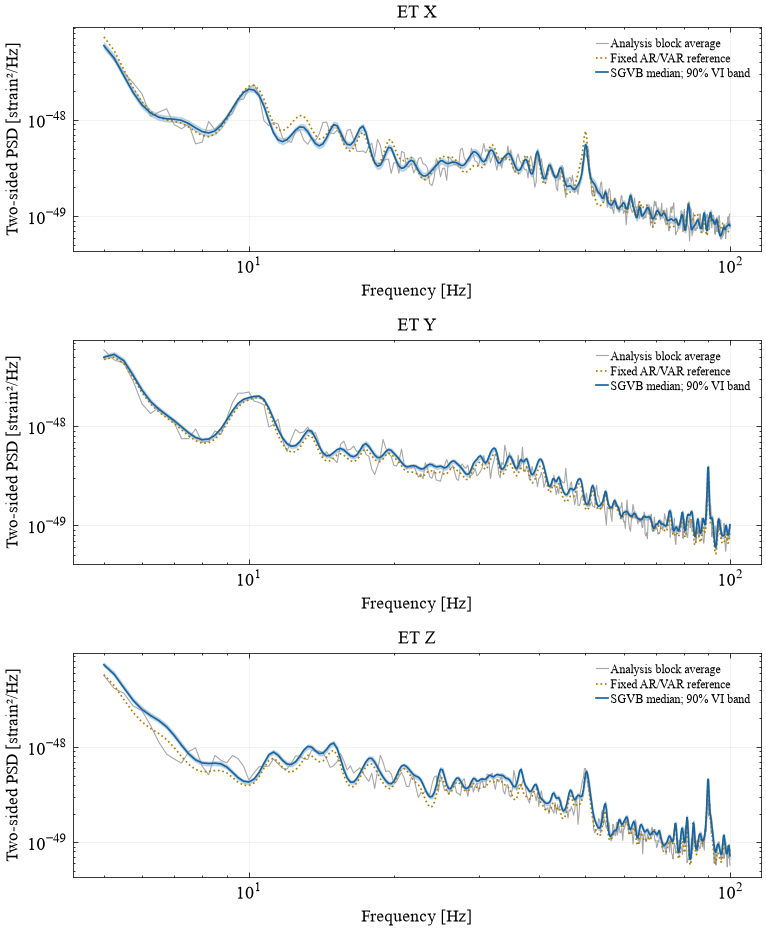

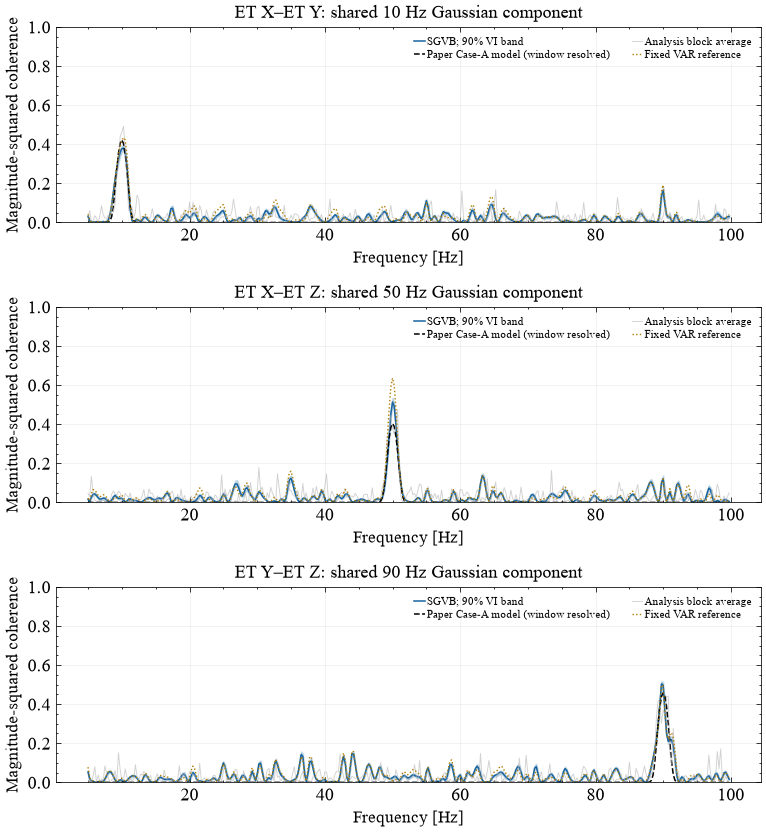

,Pair,Expected Hz,Peak Hz,SGVB peak,Paper at peak
0,ET X–ET Y,10.0,10.25,0.380,0.403
1,ET X–ET Z,50.0,50.00,0.514,0.403
2,ET Y–ET Z,90.0,89.75,0.504,0.439


In [7]:
labels = ["ET X", "ET Y", "ET Z"]
empirical, validation, baseline = show_spectra(estimator, data, heldout, labels, reference)
show_coherence(estimator, empirical, validation, baseline, labels)

## Predictive agreement and optimizer traces

Held-out plug-in Whittle score: SGVB − reference = -0.022 nats/vector (lower is better)
This is predictive agreement on one segment, not a coverage/calibration test.
ET X: fitted/held-out integrated band power = 1.005
ET Y: fitted/held-out integrated band power = 1.128
ET Z: fitted/held-out integrated band power = 1.138


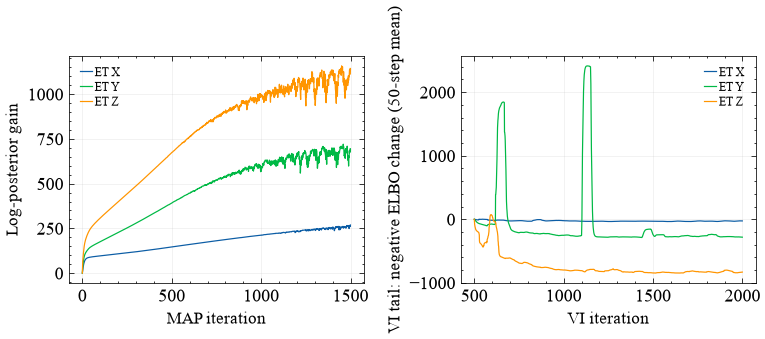

In [8]:
check_fit(estimator, validation, baseline, labels)

## What this fit demonstrates

The AR/VAR model is a cheap **fixed initial reference**. SGVB learns a smooth
residual spectral matrix and reconstructs the physical spectrum. AR order is
fixed in advance; no order search or TensorFlow installation is needed.
The independent modified-Cholesky rows are still fitted together with JAX `vmap`.

The Hann windows have unit mean-square, so no extra window-energy correction
or factor of two is applied to the returned two-sided PSD. The target is the
window-resolved spectrum of the processed data. `Nbw=1.5` is an approximate
Hann bandwidth correction for the Whittle likelihood, not an exact model of
inter-frequency dependence.

The shaded bands are 90% variational intervals **conditional on the fitted
reference**. They exclude uncertainty in AR coefficients and do not establish
calibrated coverage. Trainable variational means and four ELBO particles reduce
dependence on the final MAP iterate; inspect the displayed optimization traces
instead of treating the finite budget as a convergence certificate.
The VI panel shows the tail after iteration 500 so the large initial transient
does not hide late optimization behaviour. Held-out
scores use the posterior mean spectral matrix as a plug-in prediction; the
held-out blocks are excluded from AR and SGVB parameter fitting. This single
split is an illustrative diagnostic, not a blinded model-selection study.


The three expected Gaussian coherence peaks are checked at their proper
channel pairs. Their heights can differ from the model for this short
realization; the theoretical curve is not forced through the fit. The Hann
three-bin comparison assumes approximately independent native Fourier bins,
so it remains a window-resolution approximation.
